# 5. Speed

The two-parameter analysis of notebook 2 (source-frame primary mass $m_1^{\rm src}$ and redshift $z$, $1600 \times 1600$
grid). The comparison with nested sampling uses the 3,517 masses of notebook 2; the timing uses the 120 masses (20 to
$200\,M_\odot$) of the analysis of the paper. The only settings for speed are that all tables are kept on the GPU (about
37 GB), so nothing is copied while segments are analyzed, and that the segments are analyzed in batches.

We first check against `bilby`/`dynesty` that the analysis gives the same posteriors, then time segments over a range of
SNR on the GPU, and two segments on the CPU. The tables come from Zenodo (see the README).

In [1]:
import sys
sys.path.insert(0, '../src')

import os
import time
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
import exmarg
import exmarg.pp
import exmarg.search as search
from exmarg import figstyle

fast = dict(block=64, resident=True)
print('GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

start = time.time()
store = search.load_redshift_store('../tables/redshift', pinned=True)
print('tables read in %.0f s (once)' % (time.time() - start))

GPU: NVIDIA L40S


tables read in 23 s (once)


## The same posteriors as nested sampling

12 segments with one merger each at SNR 6 to 9, for which `bilby` sampled $m_1^{\rm src}$, $z$, the distance and the
extrinsic parameters (2000 live points, 40 CPU cores each; settings in `../scripts/run_bilby.py`).

In [2]:
segments = '../data/segments/bilby_comparison.npz'
snr = np.load(segments)['snr']
bilby = np.load('../data/results/bilby_2p_comparison.npz')

templates = search.mass_bank('../data/banks/two_parameters.npy', segments, 'gpu')
search.pe_redshift(segments, templates, store, rows=[0], **fast)        # compiles the kernels, copies the tables once

start = time.time()
result = search.pe_redshift(segments, templates, store, chunk=12, **fast)
seconds = time.time() - start
print('12 segments in %.1f s: %.2f s per segment' % (seconds, seconds / 12))
print('bilby: %.0f to %.0f s per segment on %d cores' % (bilby['wall_seconds'].min(), bilby['wall_seconds'].max(), bilby['cpu_cores'][0]))
print()
print('segment   SNR   ln B (this work)   ln B (bilby)')
for k in range(12):
    print('%7d   %4.1f   %16.2f   %7.2f +- %.2f'
          % (k, snr[k], result['ln_b'][k], bilby['e%d_ln_b' % k], bilby['e%d_ln_b_err' % k]))

12 segments in 33.0 s: 2.75 s per segment
bilby: 32 to 187 s per segment on 40 cores

segment   SNR   ln B (this work)   ln B (bilby)
      0    7.4               0.20      0.02 +- 0.02
      1    7.0               9.39      9.49 +- 0.10
      2    7.6              19.59     19.51 +- 0.11
      3    6.6               0.96      1.07 +- 0.09
      4    7.0               0.09      0.09 +- 0.05
      5    6.0              -0.01     -0.00 +- 0.01
      6    6.0               0.03      0.02 +- 0.02
      7    6.4               0.01      0.01 +- 0.03
      8    8.7               7.90      8.00 +- 0.10
      9    8.0              15.47     15.43 +- 0.10
     10    8.0               3.19      3.22 +- 0.10
     11    8.7               6.38      6.37 +- 0.09


The posteriors of two of these segments in the style of Fig. 21: ours from the run above and the `bilby` samples.
The prior is uniform in $M_{\rm det} = 2 m_1^{\rm src}(1+z)$ between 10 and 500 $M_\odot$ and proportional to $D_L^2$.
The panels of the sky position and the orientation belong to the sampler only.

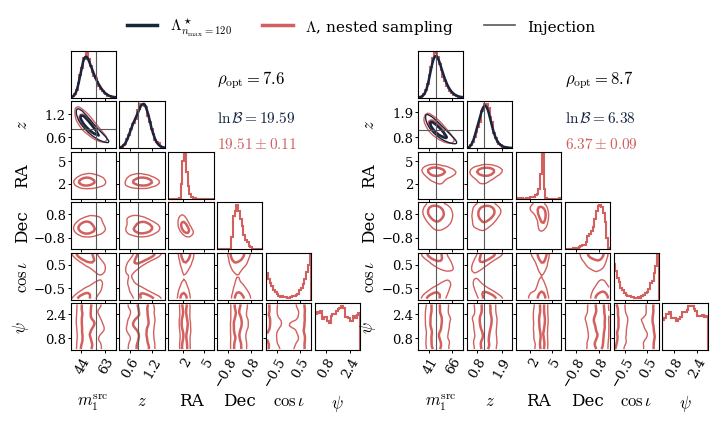

In [3]:
from astropy.cosmology import Planck18
import figures_validation as figures

m1, z = result['m1'], result['z']
DL = Planck18.luminosity_distance(z).value
prior = (1 + z) * DL ** 2 * np.gradient(DL, z)
M_det = 2 * m1[:, None] * (1 + z[None, :])
inside = (M_det >= 10) & (M_det <= 500)
truth = np.load(segments)

shown = {}
for e, k in enumerate([2, 11]):
    lp = np.where(inside, result['ln_lambda'][k] + np.log(prior)[None, :], -np.inf)
    finite = np.isfinite(lp)
    posterior = np.zeros_like(lp)
    posterior[finite] = np.exp(lp[finite] - lp[finite].max())
    posterior = posterior * np.gradient(m1)[:, None] * np.gradient(z)[None, :]
    # bilby samples inside the grid of our analysis
    keep = ((bilby['e%d_m1' % k] >= m1[0]) & (bilby['e%d_m1' % k] <= m1[-1])
            & (bilby['e%d_z' % k] >= z[0]) & (bilby['e%d_z' % k] <= z[-1]))
    shown.update({'e%d_m1_grid' % e: m1, 'e%d_z_grid' % e: z, 'e%d_ours_posterior' % e: posterior / posterior.sum(),
                  'e%d_true_m1' % e: truth['true_m1_source'][k], 'e%d_true_z' % e: truth['true_z'][k],
                  'e%d_lnB_ours' % e: result['ln_b'][k], 'e%d_lnB_bilby' % e: bilby['e%d_ln_b' % k],
                  'e%d_lnB_bilby_err' % e: bilby['e%d_ln_b_err' % k], 'e%d_rho' % e: snr[k]})
    for name in ('m1', 'z', 'ra', 'dec', 'cos_iota', 'psi'):
        shown['e%d_bilby_%s' % (e, name)] = bilby['e%d_%s' % (k, name)][keep]

figures.fig_corner_2p(shown, shown)

## Time per segment against the SNR

128 simulated 8 s segments with one equal-mass merger each, drawn by `exmarg.pp.simulate` with a fixed seed: the
detector-frame total mass uniform from 20 to $200\,M_\odot$ and the distance uniform in $\ln D_L$ between 1 and 15 Gpc,
which spreads the SNRs from below 1 to about 50. The segments are analyzed in batches of 16.

In [4]:
exmarg.detectors.set_curve('o4_gw250207')
draw = lambda rng: (rng.uniform(20.0, 200.0), 1.0, 0.0)
draw_distance = lambda rng: search.D0 / np.exp(rng.uniform(np.log(1000.0), np.log(15000.0)))     # y = D0 / D_L
segments, truth, snr = exmarg.pp.simulate(128, 20261020, draw, draw_distance, 8.0, 20.0, 512.0)
bank = np.geomspace(20.0, 200.0, 120)              # the masses of the analysis of the paper
templates = search.mass_bank(bank, segments, 'gpu')
search.pe_redshift(segments, templates, store, rows=[0], **fast)

order = np.argsort(snr)
batches = [np.sort(order[i:i + 16]) for i in range(0, order.size, 16)]
per_segment, batch_snr = [], []
start_all = time.time()
for b in batches:
    start = time.time()
    search.pe_redshift(segments, templates, store, rows=b, chunk=16, **fast)
    per_segment.append((time.time() - start) / b.size)
    batch_snr.append(np.median(snr[b]))
total = time.time() - start_all
per_segment, batch_snr = np.array(per_segment), np.array(batch_snr)
print('%d segments in %.0f s: %.3f s per segment (batches from %.3f to %.3f s per segment)'
      % (snr.size, total, total / snr.size, per_segment.min(), per_segment.max()))
print('%.0f segments per GPU hour' % (3600 * snr.size / total))

128 segments in 13 s: 0.102 s per segment (batches from 0.102 to 0.103 s per segment)
35253 segments per GPU hour


## On the CPU

The same analysis of two of these segments on the CPU, with every core of this machine (the table read runs in parallel
over the pairs of template and lag).

In [5]:
import numba
store_cpu = search.load_redshift_store('../tables/redshift', mmap=True)
templates_cpu = search.mass_bank(bank, segments, 'cpu')
rows = list(order[-2:])
search.pe_redshift(segments, templates_cpu, store_cpu, rows=rows[:1])       # compiles the CPU kernel
start = time.time()
result_cpu = search.pe_redshift(segments, templates_cpu, store_cpu, rows=rows)
seconds = time.time() - start
result_gpu = search.pe_redshift(segments, templates, store, rows=rows, **fast)
print('CPU, %d cores: %.0f s per segment' % (numba.get_num_threads(), seconds / len(rows)))
print('largest difference of ln B between the CPU and the GPU: %.1e' % np.abs(result_cpu['ln_b'] - result_gpu['ln_b']).max())

CPU, 64 cores: 3 s per segment
largest difference of ln B between the CPU and the GPU: 6.5e-06


## Against nested sampling

The wall time of one segment against its SNR. Ours is one GPU for one batch divided by the batch size; the `bilby` runs
used 32 CPU cores (three parameters), 28 cores (two parameters, the segments of Fig. 21) and 40 cores (two parameters,
the 12 segments above).

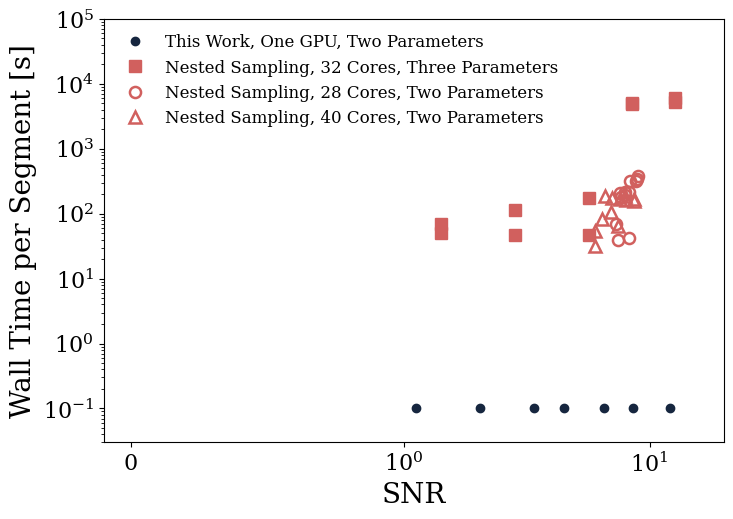

this work: 0.102 s per segment at every SNR
bilby, the 12 segments above: median 158 s on 40 cores, 1543 times longer


In [6]:
runs = np.load('../data/results/bilby_runs.npz')
three = np.load('../data/segments/three_parameters.npz')['snr'][:len(runs['three_parameters_wall_seconds'])]
two = np.load('../data/segments/two_parameters.npz')['snr']
comparison = np.load('../data/segments/bilby_comparison.npz')['snr']
valid = three <= 15

figstyle.apply()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(batch_snr, per_segment, 'o', color=figstyle.NAVY, ms=6, label='This Work, One GPU, Two Parameters')
ax.plot(three[valid], runs['three_parameters_wall_seconds'][valid], 's', color=figstyle.RED, ms=8,
        label='Nested Sampling, 32 Cores, Three Parameters')
ax.plot(two, runs['two_parameters_wall_seconds'][:two.size], 'o', mfc='none', mec=figstyle.RED, mew=1.8, ms=8,
        label='Nested Sampling, 28 Cores, Two Parameters')
ax.plot(comparison, bilby['wall_seconds'], '^', mfc='none', mec=figstyle.RED, mew=1.8, ms=8,
        label='Nested Sampling, %d Cores, Two Parameters' % bilby['cpu_cores'][0])
ax.set_xscale('symlog', linthresh=1)
ax.set_xlim(-0.1, 20)
ax.set_yscale('log')
ax.set_ylim(0.03, 1e5)
ax.set_xlabel('SNR')
ax.set_ylabel('Wall Time per Segment [s]')
ax.legend(frameon=False, loc='upper left', fontsize=12)
plt.show()

ours = total / snr.size
print('this work: %.3f s per segment at every SNR' % ours)
print('bilby, the 12 segments above: median %.0f s on %d cores, %.0f times longer'
      % (np.median(bilby['wall_seconds']), bilby['cpu_cores'][0], np.median(bilby['wall_seconds']) / ours))